# Módulo 03: Transporte de Arena en Ríos y Costas (`sedmor.river_transport`, `sedmor.coastal_transport`)

Este cuaderno implementa las herramientas de transporte de sedimentos no cohesivos en cauces fluviales con sección compuesta, integración de aforos de sedimentos en suspensión y formulación simplificada de van Rijn (2007) bajo corriente y oleaje combinados.

### Objetivos de aprendizaje
1. Evaluar el **transporte sólido en un río con llanura de inundación** por subsecciones (`compound_channel_transport`).
2. Integrar en la vertical **perfiles medidos de velocidad y concentración en suspensión** incluyendo la capa no medida cercana al fondo (`integrate_measured_suspended_transport`).
3. Cuantificar las tasas instantáneas de **transporte de fondo ($q_b$) y en suspensión ($q_s$) bajo olas y corriente** (`sand_transport_current_waves`), su promedio climático (`wave_averaged_sand_transport`) y el **balance anual flujo/reflujo** (`annual_sand_transport`).


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sedmor as sm

plt.rcParams["figure.dpi"] = 110
print(f"Librería sedmor v{sm.__version__} cargada.")


Librería sedmor v0.1.0 cargada.


## 1. Transporte Sólido Fluvial: Sección Compuesta y Aforo en Suspensión

Calculamos el reparto transversal del transporte de arena ($d_{50} = 0.30\,\text{mm}$) en un cauce con dos terrazas laterales, y luego integramos un perfil típico de laboratorio/campo de $u(z)$ y $c(z)$ mediante el método trapezoidal corregido cerca del fondo.


Transporte sólido integrado en suspensión: 0.5707 kg/(m·s)
Velocidad media: 1.305 m/s | Concentración media ponderada por flujo: 0.0735 kg/m³


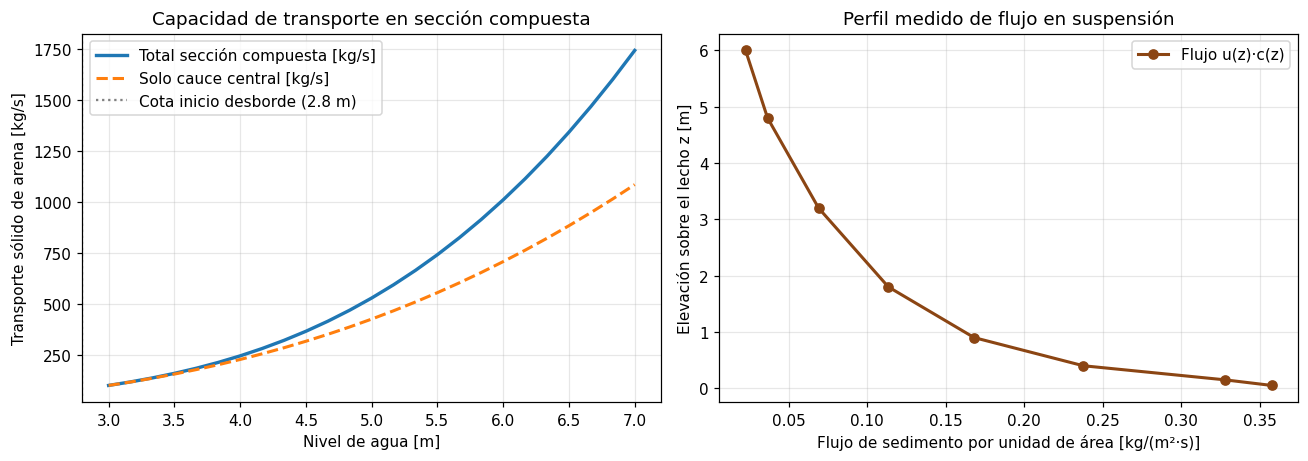

In [2]:
levels = np.linspace(3.0, 7.0, 25)
bed_levels = [2.8, 0.0, 2.8]
widths = [150.0, 80.0, 150.0]
ks_vals = [0.15, 0.04, 0.15]

qs_tot_levels = []
qs_main = []
for wl in levels:
    res_cc = sm.river_transport.compound_channel_transport(
        water_level=float(wl), slope=0.0002, bed_levels=bed_levels,
        widths=widths, ks_values=ks_vals, d50=0.0003
    )
    qs_tot_levels.append(res_cc.total_qs_mass)
    qs_main.append(res_cc.qs_mass_subsection[1])

# Aforo vertical en suspensión (ej. río aluvial de 6 m de profundidad)
z_meas = np.array([0.05, 0.15, 0.40, 0.90, 1.80, 3.20, 4.80, 6.00])
u_meas = np.array([0.55, 0.78, 0.95, 1.12, 1.26, 1.38, 1.46, 1.50])
c_meas = np.array([0.65, 0.42, 0.25, 0.15, 0.09, 0.05, 0.025, 0.015])  # kg/m3

aforo = sm.river_transport.integrate_measured_suspended_transport(z_meas, u_meas, c_meas)
print(f"Transporte sólido integrado en suspensión: {aforo.total_suspended_transport:.4f} kg/(m·s)")
print(f"Velocidad media: {aforo.depth_averaged_velocity:.3f} m/s | Concentración media ponderada por flujo: {aforo.flux_averaged_concentration:.4f} kg/m³")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.3))

ax1.plot(levels, qs_tot_levels, lw=2.2, label="Total sección compuesta [kg/s]")
ax1.plot(levels, qs_main, "--", lw=2.0, label="Solo cauce central [kg/s]")
ax1.axvline(2.8, color="gray", ls=":", label="Cota inicio desborde (2.8 m)")
ax1.set_xlabel("Nivel de agua [m]")
ax1.set_ylabel("Transporte sólido de arena [kg/s]")
ax1.set_title("Capacidad de transporte en sección compuesta")
ax1.grid(alpha=0.3)
ax1.legend()

ax2.plot(aforo.flux_profile, aforo.z, "o-", color="saddlebrown", lw=2, label="Flujo u(z)·c(z)")
ax2.set_xlabel("Flujo de sedimento por unidad de área [kg/(m²·s)]")
ax2.set_ylabel("Elevación sobre el lecho z [m]")
ax2.set_title("Perfil medido de flujo en suspensión")
ax2.grid(alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()


## 2. Transporte Costero bajo Corriente + Oleaje y Balance Anual

Estudiamos cómo el oleaje moviliza el sedimento permitiendo que una corriente moderada genere un transporte mucho mayor (`sand_transport_current_waves`), y calculamos la tasa anual neta en un punto costero sometido a un clima de 10 clases de oleaje y asimetría de marea flujo/reflujo (`annual_sand_transport`).


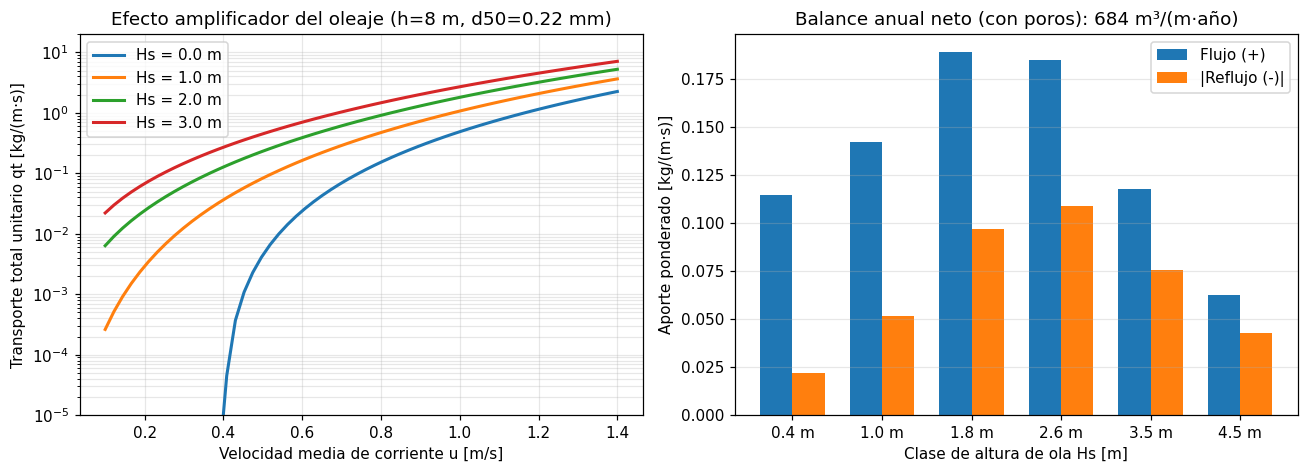

In [3]:
u_cur = np.linspace(0.1, 1.4, 60)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.4))

for hs_val in [0.0, 1.0, 2.0, 3.0]:
    cw = sm.coastal_transport.sand_transport_current_waves(
        depth=8.0, velocity=u_cur, wave_height=hs_val, wave_period=7.0, d50=0.00022, d90=0.00044
    )
    ax1.semilogy(u_cur, np.maximum(cw.qt, 1e-6), lw=2, label=f"Hs = {hs_val:.1f} m")

ax1.set_xlabel("Velocidad media de corriente u [m/s]")
ax1.set_ylabel("Transporte total unitario qt [kg/(m·s)]")
ax1.set_title("Efecto amplificador del oleaje (h=8 m, d50=0.22 mm)")
ax1.set_ylim(1e-5, 20)
ax1.grid(alpha=0.3, which="both")
ax1.legend()

# Clima anual de 6 clases (ángulo relativo, Hs [m], Tp [s], probabilidad [%])
wave_climate = (
    (0.0, 0.4, 4.0, 45.0),
    (0.0, 1.0, 5.5, 28.0),
    (0.0, 1.8, 7.0, 15.0),
    (0.0, 2.6, 8.0, 8.0),
    (0.0, 3.5, 9.0, 3.0),
    (0.0, 4.5, 10.0, 1.0),
)
ann = sm.coastal_transport.annual_sand_transport(
    depth_msl=15.0, u_flood_peak=0.75, u_ebb_peak=-0.60,
    eta_flood=1.0, eta_ebb=-1.0, wave_classes=wave_climate, d50=0.0002
)

hs_cls = [c[1] for c in wave_climate]
x_idx = np.arange(len(hs_cls))
w = 0.36
ax2.bar(x_idx - w / 2, ann.flood_kg_m_s_per_class, width=w, label="Flujo (+)")
ax2.bar(x_idx + w / 2, np.abs(ann.ebb_kg_m_s_per_class), width=w, label="|Reflujo (-)|")
ax2.set_xticks(x_idx)
ax2.set_xticklabels([f"{h:.1f} m" for h in hs_cls])
ax2.set_xlabel("Clase de altura de ola Hs [m]")
ax2.set_ylabel("Aporte ponderado [kg/(m·s)]")
ax2.set_title(f"Balance anual neto (con poros): {ann.net_vol_incl_pores_m3_yr:.0f} m³/(m·año)")
ax2.grid(alpha=0.3, axis="y")
ax2.legend()

plt.tight_layout()
plt.show()


### Ejercicios propuestos
1. Analice en `annual_sand_transport` qué fracción porcentual del transporte anual total proviene de las tormentas poco frecuentes ($H_s \ge 2.6\,\text{m}$, $4\%$ del tiempo).
2. Evalúe cómo cambia la velocidad crítica ponderada `u_cr_weighted` al pasar de arena fina ($d_{50} = 0.15\,\text{mm}$) a arena gruesa ($d_{50} = 0.60\,\text{mm}$).
